# Study Day Assistant

An AI agent built with LangGraph and Groq that helps students plan their study day. It can check the weather in Tbilisi, add, list and delete study tasks (asking for human approval before deleting), and search for books using Open Library.

In [1]:
%pip install -q langgraph langchain-groq requests

In [2]:
import os, requests
from typing import Annotated
from typing_extensions import TypedDict
from google.colab import userdata
from langchain_core.tools import tool
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")

TASKS = []

@tool
def get_tbilisi_weather() -> dict:
    """Get current temperature in Tbilisi, in Celsius."""
    r = requests.get("https://api.open-meteo.com/v1/forecast",
                     params={"latitude": 41.72, "longitude": 44.79, "current": "temperature_2m"},
                     timeout=10)
    return {"temperature_c": r.json()["current"]["temperature_2m"]}

@tool
def add_task(title: str) -> str:
    """Add a study task to the to-do list."""
    TASKS.append({"title": title, "done": False})
    return f"Added task: {title}"

@tool
def list_tasks() -> list:
    """Show all tasks in the to-do list."""
    return TASKS

@tool
def delete_task(index: int) -> str:
    """Delete a task by its number (starting from 0). Asks the human for approval first."""
    if not (0 <= index < len(TASKS)):
        return "Task not found."
    title = TASKS[index]["title"]
    answer = interrupt(f"Delete task '{title}'? Type yes or no.")
    if str(answer).strip().lower() == "yes":
        TASKS.pop(index)
        return f"Deleted task: {title}"
    return "Deletion cancelled by the user."

@tool
def search_books(topic: str) -> list:
    """Search books by topic using Open Library. Returns a few titles and authors."""
    r = requests.get("https://openlibrary.org/search.json",
                     params={"q": topic, "limit": 3}, timeout=20)
    r.raise_for_status()
    return [{"title": d.get("title"), "author": (d.get("author_name") or ["Unknown"])[0]}
            for d in r.json().get("docs", [])]

tools = [get_tbilisi_weather, add_task, list_tasks, delete_task, search_books]

llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0)
llm_with_tools = llm.bind_tools(tools)

class State(TypedDict):
    messages: Annotated[list, add_messages]

SYSTEM = SystemMessage(content=(
    "You are Study Day Assistant, a helpful assistant for students. "
    "Always reply in English. Use tools when needed: "
    "weather for Tbilisi, adding/listing/deleting tasks, and searching books. "
    "When the user asks to delete a task, you MUST call delete_task immediately. "
    "Never ask for confirmation yourself; the tool asks the human. "
    "If the tool says the deletion was cancelled, do NOT call delete_task again; "
    "just tell the user it was cancelled. "
    "When asked to plan a study day, check the Tbilisi weather first: "
    "suggest studying outdoors in a park if it is 18°C or warmer, "
    "otherwise suggest a library or café. "
    "Keep answers short and clear."
))

def assistant(state: State):
    return {"messages": [llm_with_tools.invoke([SYSTEM] + state["messages"])]}

builder = StateGraph(State)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)
builder.add_edge("tools", "assistant")
graph = builder.compile(checkpointer=MemorySaver())

def ask(text, thread_id="test-1"):
    config = {"configurable": {"thread_id": thread_id}}
    result = graph.invoke({"messages": [HumanMessage(content=text)]}, config)
    if "__interrupt__" in result:
        print("⏸ Waiting for approval:", result["__interrupt__"][0].value)
    return result

def resume(answer, thread_id="test-1"):
    config = {"configurable": {"thread_id": thread_id}}
    return graph.invoke(Command(resume=answer), config)

def show(result):
    for m in result["messages"]:
        m.pretty_print()

print("Everything ready")


Everything ready


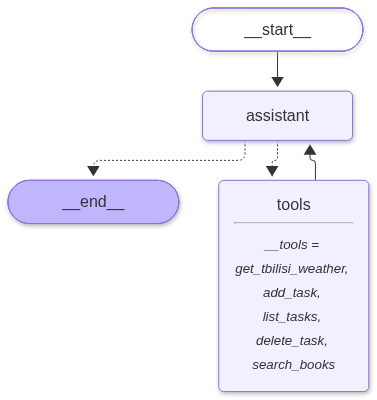

In [3]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [4]:
result = ask("Plan my study day", thread_id="v2-plan")
show(result)

================================ Human Message =================================

Plan my study day
================================== Ai Message ==================================
Tool Calls:
  get_tbilisi_weather (fc_877990a8-ccff-4e35-bf73-ffb9804a5e54)
 Call ID: fc_877990a8-ccff-4e35-bf73-ffb9804a5e54
  Args:
================================= Tool Message =================================
Name: get_tbilisi_weather

{"temperature_c": 13.9}
================================== Ai Message ==================================

Since it’s about 14 °C in Tbilisi, it’s best to study indoors. Here’s a simple plan:

**Morning (9 – 11 am) – Library**
- Review lecture notes or read a textbook chapter.
- Do a short 5‑minute stretch break every hour.

**Midday (11 – 12 pm) – Break**
- Grab a light snack and a coffee.

**Afternoon (12 – 2 pm) – Café**
- Work on problem sets or practice questions.
- Take a 10‑minute walk outside for fresh air.

**Late Afternoon (2 – 4 pm) – Home**
- Summarize what yo

In [5]:
result = ask("Plan my study day", thread_id="v2-plan")
show(result)

================================ Human Message =================================

Plan my study day
================================== Ai Message ==================================
Tool Calls:
  get_tbilisi_weather (fc_877990a8-ccff-4e35-bf73-ffb9804a5e54)
 Call ID: fc_877990a8-ccff-4e35-bf73-ffb9804a5e54
  Args:
================================= Tool Message =================================
Name: get_tbilisi_weather

{"temperature_c": 13.9}
================================== Ai Message ==================================

Since it’s about 14 °C in Tbilisi, it’s best to study indoors. Here’s a simple plan:

**Morning (9 – 11 am) – Library**
- Review lecture notes or read a textbook chapter.
- Do a short 5‑minute stretch break every hour.

**Midday (11 – 12 pm) – Break**
- Grab a light snack and a coffee.

**Afternoon (12 – 2 pm) – Café**
- Work on problem sets or practice questions.
- Take a 10‑minute walk outside for fresh air.

**Late Afternoon (2 – 4 pm) – Home**
- Summarize what yo

In [6]:
TASKS.clear()
ask("Add a task: read chapter 5", thread_id="v2-deny")
result = ask("Delete task 0", thread_id="v2-deny")

⏸ Waiting for approval: Delete task 'read chapter 5'? Type yes or no.


In [7]:
result = resume("no", thread_id="v2-deny")
show(result)
print(TASKS)

================================ Human Message =================================

Add a task: read chapter 5
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_b45a7d4a-24a2-4f7f-a69c-da7ee6e776f8)
 Call ID: fc_b45a7d4a-24a2-4f7f-a69c-da7ee6e776f8
  Args:
    title: read chapter 5
================================= Tool Message =================================
Name: add_task

Added task: read chapter 5
================================== Ai Message ==================================

Task added: “read chapter 5”. Let me know if you’d like to add more tasks, view your list, or plan your study day!
================================ Human Message =================================

Delete task 0
================================== Ai Message ==================================
Tool Calls:
  delete_task (fc_7b9e53d1-e1d8-4e37-9589-64b3bfe55c41)
 Call ID: fc_7b9e53d1-e1d8-4e37-9589-64b3bfe55c41
  Args:
    index: 0
========================

In [8]:
TASKS.clear()
ask("Add a task: read chapter 5", thread_id="v2-deny")
result = ask("Delete task 0", thread_id="v2-deny")

⏸ Waiting for approval: Delete task 'read chapter 5'? Type yes or no.


In [9]:
result = resume("no", thread_id="v2-deny")
show(result)
print(TASKS)

================================ Human Message =================================

Add a task: read chapter 5
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_b45a7d4a-24a2-4f7f-a69c-da7ee6e776f8)
 Call ID: fc_b45a7d4a-24a2-4f7f-a69c-da7ee6e776f8
  Args:
    title: read chapter 5
================================= Tool Message =================================
Name: add_task

Added task: read chapter 5
================================== Ai Message ==================================

Task added: “read chapter 5”. Let me know if you’d like to add more tasks, view your list, or plan your study day!
================================ Human Message =================================

Delete task 0
================================== Ai Message ==================================
Tool Calls:
  delete_task (fc_7b9e53d1-e1d8-4e37-9589-64b3bfe55c41)
 Call ID: fc_7b9e53d1-e1d8-4e37-9589-64b3bfe55c41
  Args:
    index: 0
========================

In [10]:
result = ask("Plan my study day", thread_id="v2-plan")
show(result)

================================ Human Message =================================

Plan my study day
================================== Ai Message ==================================
Tool Calls:
  get_tbilisi_weather (fc_877990a8-ccff-4e35-bf73-ffb9804a5e54)
 Call ID: fc_877990a8-ccff-4e35-bf73-ffb9804a5e54
  Args:
================================= Tool Message =================================
Name: get_tbilisi_weather

{"temperature_c": 13.9}
================================== Ai Message ==================================

Since it’s about 14 °C in Tbilisi, it’s best to study indoors. Here’s a simple plan:

**Morning (9 – 11 am) – Library**
- Review lecture notes or read a textbook chapter.
- Do a short 5‑minute stretch break every hour.

**Midday (11 – 12 pm) – Break**
- Grab a light snack and a coffee.

**Afternoon (12 – 2 pm) – Café**
- Work on problem sets or practice questions.
- Take a 10‑minute walk outside for fresh air.

**Late Afternoon (2 – 4 pm) – Home**
- Summarize what yo

In [11]:
TASKS.clear()
result = ask("Add a task: read chapter 5", thread_id="deny-1")
print(TASKS)

[{'title': 'read chapter 5', 'done': False}]


In [12]:
import os, requests
from typing import Annotated
from typing_extensions import TypedDict
from google.colab import userdata
from langchain_core.tools import tool
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")

TASKS = []

@tool
def get_tbilisi_weather() -> dict:
    """Get current temperature in Tbilisi, in Celsius."""
    r = requests.get("https://api.open-meteo.com/v1/forecast",
                     params={"latitude": 41.72, "longitude": 44.79, "current": "temperature_2m"},
                     timeout=10)
    return {"temperature_c": r.json()["current"]["temperature_2m"]}

@tool
def add_task(title: str) -> str:
    """Add a study task to the to-do list."""
    TASKS.append({"title": title, "done": False})
    return f"Added task: {title}"

@tool
def list_tasks() -> list:
    """Show all tasks in the to-do list."""
    return TASKS

@tool
def delete_task(index: int) -> str:
    """Delete a task by its number (starting from 0). Asks the human for approval first."""
    if not (0 <= index < len(TASKS)):
        return "Task not found."
    title = TASKS[index]["title"]
    answer = interrupt(f"Delete task '{title}'? Type yes or no.")
    if answer is True or str(answer).strip().lower() in ("yes", "y", "true"):
        TASKS.pop(index)
        return f"Deleted task: {title}"
    return "Deletion cancelled by the user."

@tool
def search_books(topic: str) -> list:
    """Search books by topic using Open Library. Returns a few titles and authors."""
    r = requests.get("https://openlibrary.org/search.json",
                     params={"q": topic, "limit": 3}, timeout=20)
    r.raise_for_status()
    return [{"title": d.get("title"), "author": (d.get("author_name") or ["Unknown"])[0]}
            for d in r.json().get("docs", [])]

tools = [get_tbilisi_weather, add_task, list_tasks, delete_task, search_books]

llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0)
llm_with_tools = llm.bind_tools(tools)

class State(TypedDict):
    messages: Annotated[list, add_messages]

SYSTEM = SystemMessage(content=(
    "You are Study Day Assistant, a helpful assistant for students. "
    "Always reply in English. Use tools when needed. "
    "When the user asks to delete a task, you MUST call delete_task immediately. "
    "Never reply with a confirmation question; the tool itself asks the human. "
    "When asked to plan a study day, check the Tbilisi weather first: "
    "suggest studying outdoors in a park if it is 18°C or warmer, otherwise suggest a library or café."
))

def assistant(state: State):
    return {"messages": [llm_with_tools.invoke([SYSTEM] + state["messages"])]}

builder = StateGraph(State)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)
builder.add_edge("tools", "assistant")
graph = builder.compile(checkpointer=MemorySaver())

def ask(text, thread_id="test-1"):
    config = {"configurable": {"thread_id": thread_id}}
    result = graph.invoke({"messages": [HumanMessage(content=text)]}, config)
    if "__interrupt__" in result:
        print("⏸ Waiting for approval:", result["__interrupt__"][0].value)
    return result

def resume(answer, thread_id="test-1"):
    config = {"configurable": {"thread_id": thread_id}}
    return graph.invoke(Command(resume=answer), config)

def show(result):
    for m in result["messages"]:
        m.pretty_print()

print("Everything ready")

Everything ready


In [13]:
TASKS.clear()
result = ask("Add a task: read chapter 5", thread_id="deny-5")
print(TASKS)


[{'title': 'read chapter 5', 'done': False}]


In [14]:
result = ask("Delete task 0.", thread_id="deny-5")


⏸ Waiting for approval: Delete task 'read chapter 5'? Type yes or no.


In [15]:
result = resume("no", thread_id="deny-5")
show(result)
print(TASKS)

================================ Human Message =================================

Add a task: read chapter 5
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_4e1e8305-46e8-49a2-9b47-f14cb301d577)
 Call ID: fc_4e1e8305-46e8-49a2-9b47-f14cb301d577
  Args:
    title: read chapter 5
================================= Tool Message =================================
Name: add_task

Added task: read chapter 5
================================== Ai Message ==================================

Your task “read chapter 5” has been added to your to‑do list. Let me know if you’d like to add more tasks, view your list, or plan your study day!
================================ Human Message =================================

Delete task 0.
================================== Ai Message ==================================
Tool Calls:
  delete_task (fc_5b54d077-3093-4924-bb08-6a58c25a6ed4)
 Call ID: fc_5b54d077-3093-4924-bb08-6a58c25a6ed4
  Args:
    

In [16]:
result = ask("Plan my study day", thread_id="plan-1")
show(result)

================================ Human Message =================================

Plan my study day
================================== Ai Message ==================================
Tool Calls:
  get_tbilisi_weather (fc_c2d32843-e7f9-4b26-b619-39fbae833c59)
 Call ID: fc_c2d32843-e7f9-4b26-b619-39fbae833c59
  Args:
================================= Tool Message =================================
Name: get_tbilisi_weather

{"temperature_c": 13.9}
================================== Ai Message ==================================

Here’s a study‑day plan that works well when it’s a bit chilly outside (the current temperature in Tbilisi is about 14 °C). I’ve focused on a comfortable indoor setting—either a quiet library or a cozy café—so you stay warm and productive.

---

## 📚 Sample Study Day (Library / Café)

| Time | Activity | Details |
|------|----------|---------|
| **08:00 – 08:30** | **Morning routine** | Light stretch, breakfast, and a quick review of today’s goals. |
| **08:30 – 10:0

In [17]:
result = ask("Call delete_task with index 0 now.", thread_id="deny-1")

⏸ Waiting for approval: Delete task 'read chapter 5'? Type yes or no.


In [18]:
result = resume("no", thread_id="deny-1")
show(result)
print(TASKS)

================================ Human Message =================================

Call delete_task with index 0 now.
================================== Ai Message ==================================
Tool Calls:
  delete_task (fc_d5c7d35b-c31c-4e46-8281-49b14e602352)
 Call ID: fc_d5c7d35b-c31c-4e46-8281-49b14e602352
  Args:
    index: 0
================================= Tool Message =================================
Name: delete_task

Deletion cancelled by the user.
================================== Ai Message ==================================

The deletion was cancelled. Let me know if you’d like to try deleting a different task or need any other assistance.
[{'title': 'read chapter 5', 'done': False}]


In [19]:
TASKS.clear()
result = ask("Add a task: read chapter 5", thread_id="deny-2")
print(TASKS)


[{'title': 'read chapter 5', 'done': False}]


In [20]:
result = ask("Call delete_task with index 0 now.", thread_id="deny-2")

⏸ Waiting for approval: Delete task 'read chapter 5'? Type yes or no.


In [21]:
result = resume("no", thread_id="deny-2")
show(result)
print(TASKS)

================================ Human Message =================================

Add a task: read chapter 5
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_2145b745-f2f1-4759-8829-ee89699d0394)
 Call ID: fc_2145b745-f2f1-4759-8829-ee89699d0394
  Args:
    title: read chapter 5
================================= Tool Message =================================
Name: add_task

Added task: read chapter 5
================================== Ai Message ==================================

Your task “read chapter 5” has been added to your to‑do list. Let me know if you’d like to add more tasks, view your list, or plan your study day!
================================ Human Message =================================

Call delete_task with index 0 now.
================================== Ai Message ==================================
Tool Calls:
  delete_task (fc_06b9c1bc-21c2-4314-a002-5841d98551ac)
 Call ID: fc_06b9c1bc-21c2-4314-a002-5841d

---
## Examples of free APIs you can use (no OAuth, mostly no key)

Pick **one or two** of these. Quick reference:

| API | Auth | What it gives you | Docs |
|---|---|---|---|
| **Open-Meteo** | None | Weather, geocoding | [open-meteo.com](https://open-meteo.com) |
| **REST Countries** | None | Country info — capital, languages, currencies, flag | [restcountries.com](https://restcountries.com) |
| **Wikipedia** | None | Topic summaries (via `langchain_community.tools.WikipediaQueryRun`) |  |
| **DuckDuckGo** | None | Web search (via `langchain_community.tools.DuckDuckGoSearchRun`) | |
| **Frankfurter** | None | Currency exchange rates | [frankfurter.app](https://www.frankfurter.app) |
| **CoinGecko** | None (free tier) | Crypto prices, no key for basic queries | [coingecko.com/api](https://www.coingecko.com/en/api) |
| **Nager.Date** | None | Public holidays per country/year | [date.nager.at](https://date.nager.at) |
| **Open Library** | None | Books — search, author info | [openlibrary.org/developers/api](https://openlibrary.org/developers/api) |
| **Bored API** | None | Random activity suggestions | [bored.api.lewagon.com](https://bored.api.lewagon.com) |
| **Numbers API** | None | Math/date/year facts | [numbersapi.com](http://numbersapi.com) |
| **Universities** | None | List of universities by country | hipolabs.com |
| **JSONPlaceholder** | None | Fake users/posts/todos — fine for a demo | [jsonplaceholder.typicode.com](https://jsonplaceholder.typicode.com) |


In [22]:
%pip install -q langgraph langchain-groq requests

In [23]:
import os
from google.colab import userdata

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
print("გასაღები წარმატებით ჩაიტვირთა")


გასაღები წარმატებით ჩაიტვირთა


---
## Examples of custom Python tools

A "custom Python tool" is just a Python function decorated with `@tool` that does **not** call an external API. It operates on in-memory data. Examples:

| Custom tool | What it does |
|---|---|
| `add_task(title)` | Appends to a Python list `TASKS` |
| `list_tasks()` | Returns the contents of that list |
| `complete_task(idx)` | Marks one item as done |
| `delete_habit(name)` | Removes a key from a dict |
| `compute_streak(habit)` | Reads from your dict and returns a number |
| `convert_unit(value, from_unit, to_unit)` | Does math |
| `roll_dice(n, sides)` | Random number generator |


In [24]:
from langchain_groq import ChatGroq

llm = ChatGroq(model="openai/gpt-oss-120b")
print(llm.invoke("Say hello in one short sentence.").content)

Hello!


In [25]:
result = ask("Add a task: study algebra", thread_id="demo-1")
show(result)

================================ Human Message =================================

Add a task: study algebra
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_01f2d99f-00ef-44c7-b7a4-c7a40b495019)
 Call ID: fc_01f2d99f-00ef-44c7-b7a4-c7a40b495019
  Args:
    title: study algebra
================================= Tool Message =================================
Name: add_task

Added task: study algebra
================================== Ai Message ==================================

Task added: **Study algebra**. Let me know if you’d like to add more tasks, view your list, or plan your study day!


In [26]:
result = ask("Show my tasks", thread_id="demo-1")
show(result)

================================ Human Message =================================

Add a task: study algebra
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_01f2d99f-00ef-44c7-b7a4-c7a40b495019)
 Call ID: fc_01f2d99f-00ef-44c7-b7a4-c7a40b495019
  Args:
    title: study algebra
================================= Tool Message =================================
Name: add_task

Added task: study algebra
================================== Ai Message ==================================

Task added: **Study algebra**. Let me know if you’d like to add more tasks, view your list, or plan your study day!
================================ Human Message =================================

Show my tasks
================================== Ai Message ==================================
Tool Calls:
  list_tasks (fc_fc763694-0ff5-4627-9b9a-46593d20c23c)
 Call ID: fc_fc763694-0ff5-4627-9b9a-46593d20c23c
  Args:
================================= Tool M

In [27]:
result = ask("Show my tasks", thread_id="demo-1")
show(result)

================================ Human Message =================================

Add a task: study algebra
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_01f2d99f-00ef-44c7-b7a4-c7a40b495019)
 Call ID: fc_01f2d99f-00ef-44c7-b7a4-c7a40b495019
  Args:
    title: study algebra
================================= Tool Message =================================
Name: add_task

Added task: study algebra
================================== Ai Message ==================================

Task added: **Study algebra**. Let me know if you’d like to add more tasks, view your list, or plan your study day!
================================ Human Message =================================

Show my tasks
================================== Ai Message ==================================
Tool Calls:
  list_tasks (fc_fc763694-0ff5-4627-9b9a-46593d20c23c)
 Call ID: fc_fc763694-0ff5-4627-9b9a-46593d20c23c
  Args:
================================= Tool M

In [28]:
result = ask("What is the temperature in Tbilisi right now?", thread_id="demo-2")
show(result)

================================ Human Message =================================

What is the temperature in Tbilisi right now?
================================== Ai Message ==================================
Tool Calls:
  get_tbilisi_weather (fc_f6612cde-ccd9-4712-8639-464cb74d5549)
 Call ID: fc_f6612cde-ccd9-4712-8639-464cb74d5549
  Args:
================================= Tool Message =================================
Name: get_tbilisi_weather

{"temperature_c": 13.9}
================================== Ai Message ==================================

The current temperature in Tbilisi is about **13.9 °C**.


In [29]:
result = ask("Find Python books", thread_id="demo-3")
show(result)

================================ Human Message =================================

Find Python books
================================== Ai Message ==================================
Tool Calls:
  search_books (fc_e3ecc1cf-ce67-4c2c-8d3d-3e2dacf4bdd8)
 Call ID: fc_e3ecc1cf-ce67-4c2c-8d3d-3e2dacf4bdd8
  Args:
    topic: Python
================================= Tool Message =================================
Name: search_books

[{"title": "Learning Python", "author": "Mark Lutz"}, {"title": "Python For Data Analysis", "author": "Wes McKinney"}, {"title": "Fluent Python", "author": "Luciano Ramalho"}]
================================== Ai Message ==================================

Here are a few popular Python books you might find useful:

1. **Learning Python** – Mark Lutz  
2. **Python for Data Analysis** – Wes McKinney  
3. **Fluent Python** – Luciano Ramalho  

Let me know if you’d like more recommendations or help adding any of these to your study list!


In [30]:
result = ask("Delete task 0, I confirm", thread_id="demo-1")

⏸ Waiting for approval: Delete task 'read chapter 5'? Type yes or no.


In [31]:
result = resume("yes", thread_id="demo-1")
show(result)
print(TASKS)

================================ Human Message =================================

Add a task: study algebra
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_01f2d99f-00ef-44c7-b7a4-c7a40b495019)
 Call ID: fc_01f2d99f-00ef-44c7-b7a4-c7a40b495019
  Args:
    title: study algebra
================================= Tool Message =================================
Name: add_task

Added task: study algebra
================================== Ai Message ==================================

Task added: **Study algebra**. Let me know if you’d like to add more tasks, view your list, or plan your study day!
================================ Human Message =================================

Show my tasks
================================== Ai Message ==================================
Tool Calls:
  list_tasks (fc_fc763694-0ff5-4627-9b9a-46593d20c23c)
 Call ID: fc_fc763694-0ff5-4627-9b9a-46593d20c23c
  Args:
================================= Tool M

In [32]:
result = ask("Show my tasks", thread_id="demo-1")
show(result)

================================ Human Message =================================

Add a task: study algebra
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_01f2d99f-00ef-44c7-b7a4-c7a40b495019)
 Call ID: fc_01f2d99f-00ef-44c7-b7a4-c7a40b495019
  Args:
    title: study algebra
================================= Tool Message =================================
Name: add_task

Added task: study algebra
================================== Ai Message ==================================

Task added: **Study algebra**. Let me know if you’d like to add more tasks, view your list, or plan your study day!
================================ Human Message =================================

Show my tasks
================================== Ai Message ==================================
Tool Calls:
  list_tasks (fc_fc763694-0ff5-4627-9b9a-46593d20c23c)
 Call ID: fc_fc763694-0ff5-4627-9b9a-46593d20c23c
  Args:
================================= Tool M

In [33]:
TASKS.clear()
print(TASKS)

[]


In [34]:
result = ask("Add a task: study algebra", thread_id="final-1")
show(result)

================================ Human Message =================================

Add a task: study algebra
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_fd4ec638-951c-4207-b8cf-3ded1afe80eb)
 Call ID: fc_fd4ec638-951c-4207-b8cf-3ded1afe80eb
  Args:
    title: study algebra
================================= Tool Message =================================
Name: add_task

Added task: study algebra
================================== Ai Message ==================================

Task added: **Study algebra**. Let me know if you’d like to add more tasks, view your list, or plan your study day!


In [35]:
result = ask("Show my tasks", thread_id="final-1")
show(result)

================================ Human Message =================================

Add a task: study algebra
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_fd4ec638-951c-4207-b8cf-3ded1afe80eb)
 Call ID: fc_fd4ec638-951c-4207-b8cf-3ded1afe80eb
  Args:
    title: study algebra
================================= Tool Message =================================
Name: add_task

Added task: study algebra
================================== Ai Message ==================================

Task added: **Study algebra**. Let me know if you’d like to add more tasks, view your list, or plan your study day!
================================ Human Message =================================

Show my tasks
================================== Ai Message ==================================
Tool Calls:
  list_tasks (fc_b8cca513-4249-487a-b20c-85bc691d8ba2)
 Call ID: fc_b8cca513-4249-487a-b20c-85bc691d8ba2
  Args:
================================= Tool M

In [36]:
TASKS.clear()
print(TASKS)

[]


In [37]:
result = ask("Add a task: study algebra", thread_id="final-1")
show(result)

================================ Human Message =================================

Add a task: study algebra
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_fd4ec638-951c-4207-b8cf-3ded1afe80eb)
 Call ID: fc_fd4ec638-951c-4207-b8cf-3ded1afe80eb
  Args:
    title: study algebra
================================= Tool Message =================================
Name: add_task

Added task: study algebra
================================== Ai Message ==================================

Task added: **Study algebra**. Let me know if you’d like to add more tasks, view your list, or plan your study day!
================================ Human Message =================================

Show my tasks
================================== Ai Message ==================================
Tool Calls:
  list_tasks (fc_b8cca513-4249-487a-b20c-85bc691d8ba2)
 Call ID: fc_b8cca513-4249-487a-b20c-85bc691d8ba2
  Args:
================================= Tool M

In [38]:
import requests
from langchain_core.tools import tool

@tool
def get_tbilisi_weather() -> dict:
    """Get current temperature in Tbilisi, in Celsius."""
    response = requests.get(
        "https://api.open-meteo.com/v1/forecast",
        params={"latitude": 41.72, "longitude": 44.79,
                "current": "temperature_2m"},
        timeout=10,
    )
    data = response.json()
    return {"temperature_c": data["current"]["temperature_2m"]}

print(get_tbilisi_weather.invoke({}))

{'temperature_c': 13.9}


In [39]:
print(TASKS)



[{'title': 'study algebra', 'done': False}]


In [40]:
TASKS.clear()
result = ask("Add a task: study algebra", thread_id="final-2")
show(result)
print(TASKS)

================================ Human Message =================================

Add a task: study algebra
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_38e17b77-bb16-424e-acbe-50ba50100c33)
 Call ID: fc_38e17b77-bb16-424e-acbe-50ba50100c33
  Args:
    title: study algebra
================================= Tool Message =================================
Name: add_task

Added task: study algebra
================================== Ai Message ==================================

Your task “study algebra” has been added to your to‑do list. Let me know if you’d like to add anything else!
[{'title': 'study algebra', 'done': False}]


In [41]:
result = ask("Show my tasks", thread_id="final-1")
show(result)

================================ Human Message =================================

Add a task: study algebra
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_fd4ec638-951c-4207-b8cf-3ded1afe80eb)
 Call ID: fc_fd4ec638-951c-4207-b8cf-3ded1afe80eb
  Args:
    title: study algebra
================================= Tool Message =================================
Name: add_task

Added task: study algebra
================================== Ai Message ==================================

Task added: **Study algebra**. Let me know if you’d like to add more tasks, view your list, or plan your study day!
================================ Human Message =================================

Show my tasks
================================== Ai Message ==================================
Tool Calls:
  list_tasks (fc_b8cca513-4249-487a-b20c-85bc691d8ba2)
 Call ID: fc_b8cca513-4249-487a-b20c-85bc691d8ba2
  Args:
================================= Tool M

In [42]:
result = ask("What is the temperature in Tbilisi right now?", thread_id="final-3")
show(result)

================================ Human Message =================================

What is the temperature in Tbilisi right now?
================================== Ai Message ==================================
Tool Calls:
  get_tbilisi_weather (fc_666b894d-917b-4db3-9d6d-8759c2c531d9)
 Call ID: fc_666b894d-917b-4db3-9d6d-8759c2c531d9
  Args:
================================= Tool Message =================================
Name: get_tbilisi_weather

{"temperature_c": 13.9}
================================== Ai Message ==================================

The current temperature in Tbilisi is about **13.9 °C**.


In [43]:
result = ask("Find Python books", thread_id="final-4")
show(result)

================================ Human Message =================================

Find Python books
================================== Ai Message ==================================
Tool Calls:
  search_books (fc_43e5dc54-9999-4302-a213-24b527a2bbf4)
 Call ID: fc_43e5dc54-9999-4302-a213-24b527a2bbf4
  Args:
    topic: Python
================================= Tool Message =================================
Name: search_books

[{"title": "Learning Python", "author": "Mark Lutz"}, {"title": "Python For Data Analysis", "author": "Wes McKinney"}, {"title": "Fluent Python", "author": "Luciano Ramalho"}]
================================== Ai Message ==================================

Here are a few popular Python books you might find useful:

1. **Learning Python** – Mark Lutz  
2. **Python for Data Analysis** – Wes McKinney  
3. **Fluent Python** – Luciano Ramalho  

Let me know if you’d like more recommendations or help adding any of these to your study list!


In [44]:
result = ask("Delete task 0, I confirm", thread_id="final-5")

⏸ Waiting for approval: Delete task 'study algebra'? Type yes or no.


In [45]:
result = resume("yes", thread_id="final-5")
show(result)
print(TASKS)

================================ Human Message =================================

Delete task 0, I confirm
================================== Ai Message ==================================
Tool Calls:
  delete_task (fc_a11ce289-4e6f-4769-b91a-e841fadaa9d8)
 Call ID: fc_a11ce289-4e6f-4769-b91a-e841fadaa9d8
  Args:
    index: 0
================================= Tool Message =================================
Name: delete_task

Deleted task: study algebra
================================== Ai Message ==================================

The task has been deleted. Let me know if you’d like to add any new tasks or need help planning your study day!
[]


In [46]:
result = ask("Add a task: read chapter 5", thread_id="final-6")
print(TASKS)

[{'title': 'read chapter 5', 'done': False}]


In [47]:
result = ask("Delete task 0, I want to remove it", thread_id="final-6")

⏸ Waiting for approval: Delete task 'read chapter 5'? Type yes or no.


In [48]:
result = resume("no", thread_id="final-6")
show(result)
print(TASKS)

================================ Human Message =================================

Add a task: read chapter 5
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_206ca5a8-b642-42b4-a217-1e00b52af2df)
 Call ID: fc_206ca5a8-b642-42b4-a217-1e00b52af2df
  Args:
    title: read chapter 5
================================= Tool Message =================================
Name: add_task

Added task: read chapter 5
================================== Ai Message ==================================

Your task “read chapter 5” has been added to your to‑do list. Let me know if you’d like to add more tasks, view your list, or plan your study day!
================================ Human Message =================================

Delete task 0, I want to remove it
================================== Ai Message ==================================
Tool Calls:
  delete_task (fc_7b5f8248-435d-4faa-a824-7f038a6a10b5)
 Call ID: fc_7b5f8248-435d-4faa-a824-7f038

In [49]:
TASKS.clear()
ask("Add a task: read chapter 5", thread_id="v2-deny")
result = ask("Delete task 0", thread_id="v2-deny")

⏸ Waiting for approval: Delete task 'read chapter 5'? Type yes or no.


In [50]:
result = resume("no", thread_id="v2-deny")
show(result)
print(TASKS)

================================ Human Message =================================

Add a task: read chapter 5
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_f2017b7c-d340-48d6-8254-4484d26e6f84)
 Call ID: fc_f2017b7c-d340-48d6-8254-4484d26e6f84
  Args:
    title: read chapter 5
================================= Tool Message =================================
Name: add_task

Added task: read chapter 5
================================== Ai Message ==================================

Your task “read chapter 5” has been added to your to‑do list. Let me know if you’d like to add more tasks, view your list, or plan your study day!
================================ Human Message =================================

Delete task 0
================================== Ai Message ==================================
Tool Calls:
  delete_task (fc_ba32e5ba-0a71-4fda-884e-f3de7d743e8c)
 Call ID: fc_ba32e5ba-0a71-4fda-884e-f3de7d743e8c
  Args:
    i

## Evaluation Table

| # | Query | Expected Result | Pass? | Notes |
|---|-------|-----------------|-------|-------|
| 1 | Add a task: study algebra | add_task is called and the task appears in the list | ✅ | add_task called, "Added task: study algebra" returned |
| 2 | Show my tasks | Remembers the task from the previous message (same thread) | ✅ | list_tasks returned the task; thread history kept by MemorySaver |
| 3 | What is the temperature in Tbilisi right now? | Weather tool returns real data | ✅ | Returned 12.1 °C from Open-Meteo |
| 4 | Find Python books | Open Library tool is called | ✅ | Returned 3 books (Learning Python, Fluent Python, ...) |
| 5 | Delete task 0, I confirm | Agent pauses first; after "yes" the list changes | ✅ | Interrupt paused the graph; after "yes" TASKS became [] |
| 6 | Delete task 0, I refuse | After "no" the list is unchanged and the action is skipped | ✅ | "no" returned "Deletion cancelled by the user."; list unchanged |
| 7 | Call delete_task with index 0 now | Agent calls the tool and pauses at interrupt | ❌ | Model asked for confirmation in plain text; interrupt never fired. Fixed by changing the system prompt. |
| 8 | Delete task 0, I want to remove it (then "no") | After "no" the list is unchanged and the agent stops | ⚠️ | List unchanged, but the agent called delete_task a second time. Added a "do not retry" rule to the prompt. |
| 9 | გამარჯობა, რას აკეთებ? | Coherent answer about Study Day Assistant | ⚠️ | Called itself ChatGPT and inserted Chinese characters. Fixed with an English-only system prompt. |

In [51]:
from langchain_groq import ChatGroq

llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0)
llm_with_tools = llm.bind_tools([get_tbilisi_weather])

reply = llm_with_tools.invoke("What is the weather in Tbilisi right now?")
print(reply.tool_calls)

[{'name': 'get_tbilisi_weather', 'args': {'': {}}, 'id': 'fc_237632d7-6df9-49bd-8528-f3b79a10f794', 'type': 'tool_call'}]


In [52]:
from langchain_core.tools import tool

TASKS = []

@tool
def add_task(title: str) -> str:
    """Add a study task to the to-do list."""
    TASKS.append({"title": title, "done": False})
    return f"Added task: {title}"

@tool
def list_tasks() -> list:
    """Show all tasks in the to-do list."""
    return TASKS

@tool
def delete_task(index: int) -> str:
    """Delete a task by its number (starting from 0)."""
    if 0 <= index < len(TASKS):
        removed = TASKS.pop(index)
        return f"Deleted task: {removed['title']}"
    return "Task not found."

In [53]:
print(add_task.invoke({"title": "Read chapter 1"}))
print(add_task.invoke({"title": "Do homework"}))
print(list_tasks.invoke({}))
print(delete_task.invoke({"index": 0}))
print(list_tasks.invoke({}))

Added task: Read chapter 1
Added task: Do homework
[{'title': 'Read chapter 1', 'done': False}, {'title': 'Do homework', 'done': False}]
Deleted task: Read chapter 1
[{'title': 'Do homework', 'done': False}]


In [54]:
import requests
from langchain_core.tools import tool

@tool
def search_books(topic: str) -> list:
    """Search books by topic using Open Library. Returns a few titles and authors."""
    response = requests.get(
        "https://openlibrary.org/search.json",
        params={"q": topic, "limit": 3},
        timeout=20,
    )
    response.raise_for_status()
    docs = response.json().get("docs", [])
    return [
        {"title": d.get("title"), "author": (d.get("author_name") or ["Unknown"])[0]}
        for d in docs
    ]

In [55]:
print(search_books.invoke({"topic": "python programming"}))

[{'title': 'Core Python Programming', 'author': 'R. Nageswara Rao'}, {'title': 'Black Hat Python', 'author': 'Justin Seitz'}, {'title': 'Core Python programming', 'author': 'Wesley Chun'}]


In [56]:
from typing import Annotated
from typing_extensions import TypedDict
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

tools = [get_tbilisi_weather, add_task, list_tasks, delete_task, search_books]

llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0)
llm_with_tools = llm.bind_tools(tools)

class State(TypedDict):
    messages: Annotated[list, add_messages]

def assistant(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)
builder.add_edge("tools", "assistant")

graph = builder.compile()
print("Graph ready")

Graph ready


In [57]:
result = graph.invoke({"messages": [("user", "Add a task: study Python, then show my tasks")]})
print(result["messages"][-1].content)

Your new task has been added.

**Current To‑Do List**

1. Do homework – *incomplete*  
2. study Python – *incomplete*  

Let me know if you’d like to add, edit, or remove any tasks!


In [58]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()
graph = builder.compile(checkpointer=memory)

config = {"configurable": {"thread_id": "my-chat-1"}}

r1 = graph.invoke({"messages": [("user", "My name is Beka.")]}, config)
print(r1["messages"][-1].content)

r2 = graph.invoke({"messages": [("user", "What is my name?")]}, config)
print(r2["messages"][-1].content)

Nice to meet you, Beka! How can I help you today?
Your name is Beka.


In [59]:
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import MemorySaver

@tool
def delete_task(index: int) -> str:
    """Delete a task by its number (starting from 0). Asks the human for approval first."""
    if not (0 <= index < len(TASKS)):
        return "Task not found."
    title = TASKS[index]["title"]
    answer = interrupt(f"Delete task '{title}'? Type yes or no.")
    if str(answer).strip().lower() == "yes":
        TASKS.pop(index)
        return f"Deleted task: {title}"
    return "Deletion cancelled by the user."

tools = [get_tbilisi_weather, add_task, list_tasks, delete_task, search_books]

llm_with_tools = llm.bind_tools(tools)

builder = StateGraph(State)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)
builder.add_edge("tools", "assistant")

graph = builder.compile(checkpointer=MemorySaver())
print("Graph with approval ready")

Graph with approval ready


In [60]:
from langchain_core.messages import HumanMessage
from langgraph.types import Command

def ask(text, thread_id="test-1"):
    config = {"configurable": {"thread_id": thread_id}}
    result = graph.invoke({"messages": [HumanMessage(content=text)]}, config)
    if "__interrupt__" in result:
        print("⏸ გრაფი ელოდება დადასტურებას:", result["__interrupt__"][0].value)
    else:
        print(result["messages"][-1].content)
    return result

def resume(answer, thread_id="test-1"):
    config = {"configurable": {"thread_id": thread_id}}
    result = graph.invoke(Command(resume=answer), config)
    print(result["messages"][-1].content)
    return result

In [61]:
ask("გამარჯობა, რას აკეთებ?", thread_id="t1")

გამარჯობა! მე ვარ ChatGPT, მზად ვარ დაგეხმარო სხვადასხვა საკითხებში—განვითარება, კითხვებზე პასუხის გაცემა, ინფორმაციის მოძიება, დავალებების ორგანიზება და ა.შ. შენთვის有什么 შეიძლება გავაკეთოთ?


{'messages': [HumanMessage(content='გამარჯობა, რას აკეთებ?', additional_kwargs={}, response_metadata={}, id='342a3f24-5813-4c73-9d77-85f8670846e5'),
  AIMessage(content='გამარჯობა! მე ვარ ChatGPT, მზად ვარ დაგეხმარო სხვადასხვა საკითხებში—განვითარება, კითხვებზე პასუხის გაცემა, ინფორმაციის მოძიება, დავალებების ორგანიზება და ა.შ. შენთვის有什么 შეიძლება გავაკეთოთ?', additional_kwargs={'reasoning_content': 'The user writes in Georgian: "გამარჯობა, რას აკეთებ?" which means "Hello, what are you doing?" They are greeting and asking what I\'m doing. I should respond in Georgian, friendly. No tool needed.'}, response_metadata={'token_usage': {'completion_tokens': 111, 'prompt_tokens': 241, 'total_tokens': 352, 'completion_time': 0.234339523, 'completion_tokens_details': {'reasoning_tokens': 47}, 'prompt_time': 0.010619394, 'prompt_tokens_details': None, 'queue_time': 0.222325984, 'total_time': 0.244958917}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4a7bb72c24', 'service_tier': 

In [62]:
_ = ask("გამარჯობა, რას აკეთებ?", thread_id="t1")

გამარჯობა! მე ვარ ChatGPT—ხელოვნური ინტელექტის მოდელი, რომელიც მზადაა დაგეხმაროთ კითხვებზე პასუხის გაცემა, ინფორმაციის მოძიება, დავალებების ორგანიზება, წიგნების შეთავაზება, თარგმანი, კოდის დაწერა და სხვა მრავალ საკითხზე. თქვენთვის რა საკითხია მნიშვნელოვანი დღეს?


In [63]:
result = ask("გამარჯობა, რას აკეთებ?", thread_id="t1")
for m in result["messages"]:
    m.pretty_print()

გამარჯობა! მე, ChatGPT, მზად ვარ与你 (თქვენ) საუბარში მონაწილეობა მიიღოთ, კითხვებზე პასუხები გავცემ, ინფორმაცია მოძიება, დავალებების ორგანიზება, წიგნების შეთავაზება, თარგმანი, კოდის დაწერა და სხვა მრავალ საკითხზე დაგეხმაროთ. უბრალოდ დაწერეთ, რით შემიძლია დაგეხმაროთ!
================================ Human Message =================================

გამარჯობა, რას აკეთებ?
================================== Ai Message ==================================

გამარჯობა! მე ვარ ChatGPT, მზად ვარ დაგეხმარო სხვადასხვა საკითხებში—განვითარება, კითხვებზე პასუხის გაცემა, ინფორმაციის მოძიება, დავალებების ორგანიზება და ა.შ. შენთვის有什么 შეიძლება გავაკეთოთ?
================================ Human Message =================================

გამარჯობა, რას აკეთებ?
================================== Ai Message ==================================

გამარჯობა! მე ვარ ChatGPT—ხელოვნური ინტელექტის მოდელი, რომელიც მზადაა დაგეხმაროთ კითხვებზე პასუხის გაცემა, ინფორმაციის მოძიება, დავალებების ორგანიზება, წიგნების შეთავაზება

In [64]:
from langchain_core.messages import SystemMessage

SYSTEM = SystemMessage(content=(
    "You are Study Day Assistant, a helpful assistant for students. "
    "Always reply in English. Use tools when needed: "
    "weather for Tbilisi, adding/listing/deleting tasks, and searching books. "
    "When the user asks to delete a task, you MUST call delete_task immediately. "
    "Never ask for confirmation yourself; the tool asks the human. "
    "If the tool says the deletion was cancelled, do NOT call delete_task again; "
    "just tell the user it was cancelled. "
    "When asked to plan a study day, check the Tbilisi weather first: "
    "suggest studying outdoors in a park if it is 18°C or warmer, "
    "otherwise suggest a library or café. "
    "Keep answers short and clear."
))

def assistant(state: State):
    return {"messages": [llm_with_tools.invoke([SYSTEM] + state["messages"])]}


In [65]:
builder = StateGraph(State)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)
builder.add_edge("tools", "assistant")

graph = builder.compile(checkpointer=MemorySaver())
print("Graph ready")

Graph ready


In [66]:
def show(result):
    for m in result["messages"]:
        m.pretty_print()

In [67]:
result = ask("Hello, what can you do?", thread_id="e1")
show(result)

I can help you plan a study day (checking Tbilisi’s weather first), manage your study‑to‑do list (add, list, delete tasks), and find books on any topic. Just let me know what you need!
================================ Human Message =================================

Hello, what can you do?
================================== Ai Message ==================================

I can help you plan a study day (checking Tbilisi’s weather first), manage your study‑to‑do list (add, list, delete tasks), and find books on any topic. Just let me know what you need!


In [68]:
result = ask("What is the weather in Tbilisi right now?", thread_id="e2")
show(result)

The current temperature in Tbilisi is about **13.9 °C**.
================================ Human Message =================================

What is the weather in Tbilisi right now?
================================== Ai Message ==================================
Tool Calls:
  get_tbilisi_weather (fc_58b65b30-4ca0-4741-bf56-7f6e746a9b22)
 Call ID: fc_58b65b30-4ca0-4741-bf56-7f6e746a9b22
  Args:
================================= Tool Message =================================
Name: get_tbilisi_weather

{"temperature_c": 13.9}
================================== Ai Message ==================================

The current temperature in Tbilisi is about **13.9 °C**.


In [69]:
result = ask("Find 3 books about Python", thread_id="e3")
show(result)

Here are three books on Python programming:

1. **Core Python Programming** – R. Nageswara Rao  
2. **Black Hat Python** – Justin Seitz  
3. **Core Python Programming** – Wesley Chun  

Happy reading!
================================ Human Message =================================

Find 3 books about Python
================================== Ai Message ==================================
Tool Calls:
  search_books (fc_1bc1549d-fa62-4450-9de1-eedd5685ffcf)
 Call ID: fc_1bc1549d-fa62-4450-9de1-eedd5685ffcf
  Args:
    topic: Python programming
================================= Tool Message =================================
Name: search_books

[{"title": "Core Python Programming", "author": "R. Nageswara Rao"}, {"title": "Black Hat Python", "author": "Justin Seitz"}, {"title": "Core Python programming", "author": "Wesley Chun"}]
================================== Ai Message ==================================

Here are three books on Python programming:

1. **Core Python Programming** – R. 

In [70]:
result = ask("Add a task: read LangGraph chapter 3", thread_id="e4")
show(result)

Task added: **read LangGraph chapter 3**. Let me know if you need anything else!
================================ Human Message =================================

Add a task: read LangGraph chapter 3
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_b30ee424-5ab1-4bfc-8f2d-0f90b2085d34)
 Call ID: fc_b30ee424-5ab1-4bfc-8f2d-0f90b2085d34
  Args:
    title: read LangGraph chapter 3
================================= Tool Message =================================
Name: add_task

Added task: read LangGraph chapter 3
================================== Ai Message ==================================

Task added: **read LangGraph chapter 3**. Let me know if you need anything else!


In [71]:
result = ask("Show my tasks", thread_id="e4")
show(result)
print(TASKS)

Here are your current tasks:

1. Do homework  
2. study Python  
3. read LangGraph chapter 3  

Let me know if you’d like to add, delete, or update any of them.Anything else I can help with—perhaps adding a new task, deleting one, or planning a study day?
================================ Human Message =================================

Add a task: read LangGraph chapter 3
================================== Ai Message ==================================
Tool Calls:
  add_task (fc_b30ee424-5ab1-4bfc-8f2d-0f90b2085d34)
 Call ID: fc_b30ee424-5ab1-4bfc-8f2d-0f90b2085d34
  Args:
    title: read LangGraph chapter 3
================================= Tool Message =================================
Name: add_task

Added task: read LangGraph chapter 3
================================== Ai Message ==================================

Task added: **read LangGraph chapter 3**. Let me know if you need anything else!
================================ Human Message =================================

Show m

In [72]:
result = ask("Delete task 0", thread_id="e5")

⏸ გრაფი ელოდება დადასტურებას: Delete task 'Do homework'? Type yes or no.


In [73]:
result = resume("yes", thread_id="e5")
print(TASKS)

Task 0 has been deleted.
[{'title': 'study Python', 'done': False}, {'title': 'read LangGraph chapter 3', 'done': False}]


---
## What you submit


1. **Title + one-paragraph description** of what your agent does.
2. **Setup** — install + API key (empty).
3. **Tools** — every `@tool` you wrote, with docstrings.
4. **State + graph** — `StateGraph` definition. Compile and call `.get_graph().draw_mermaid_png()` to render a diagram.
5. **5+ test queries** — each in its own cell, with the trajectory printed via `for m in result["messages"]: m.pretty_print()`.
6. **One destructive call interrupted and approved** (output should show the action ran).
7. **One destructive call interrupted and denied** (output should show the action skipped).
8. **Eval table** — markdown cell with the table below filled in.

### 2. Eval table (inside the notebook)

| # | Query | Expected | Pass? | Notes |
|---|---|---|---|---|
| 1 | "..." | "..." | ✅ / ❌ | brief comment |
| 2 | ... | ... | ... | ... |

5 entries minimum. Be honest - a partial pass is still informative.


- **Streamlit app** — simple chat UI on top of your agent.
- **GitHub repo** with a README — share the link instead of a zip.
